# RC BUILDING
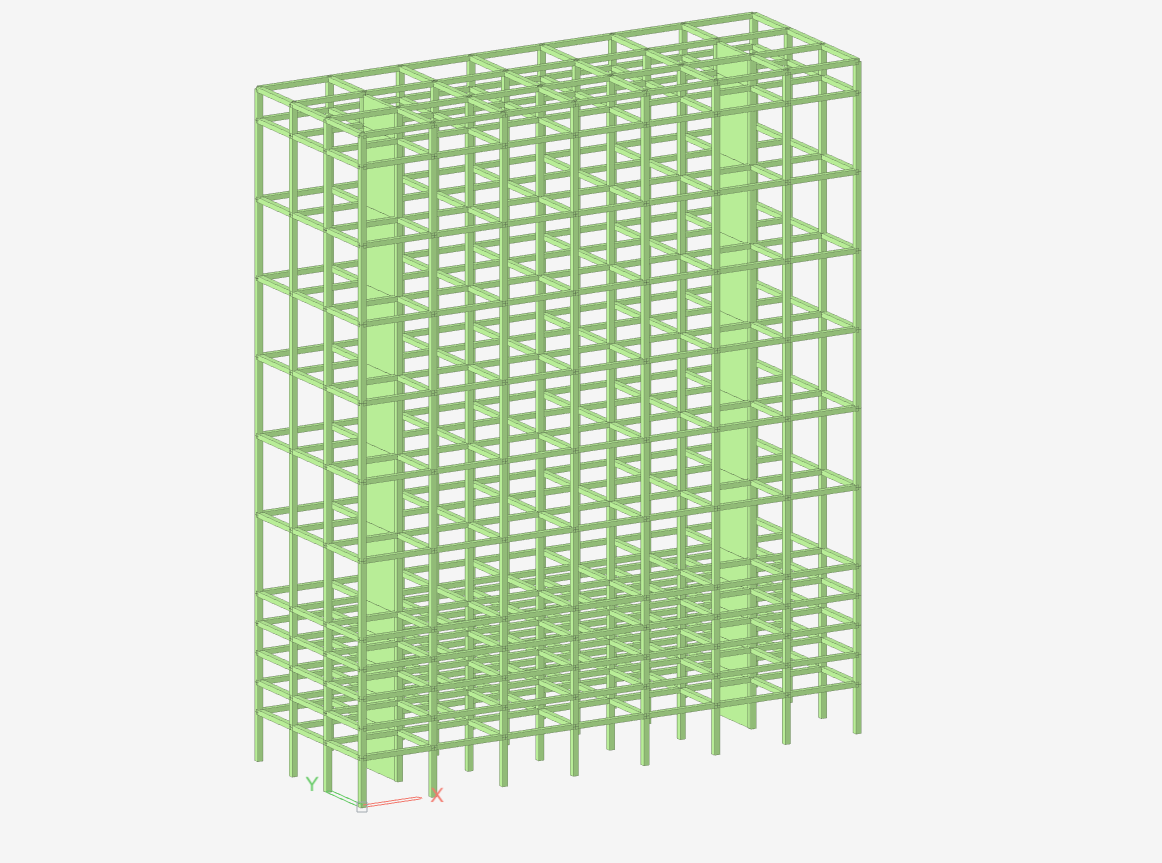

In [ ]:
from midas_gen import *
MAPI_KEY('eyJ1ciI6IklOMjUwNEo1UUEiLCJwZyI6ImdlbiIsImNuIjoiVTl2MDZiaTdSdyJ9.cafba89a573eb662e4eb641416f107913f22fbdb1b83532a6e8979a83b2078be')
MAPI_BASEURL.autoURL()


Floor_Height = ["1@5,4@3,6@8,1@3.15"] # Format: "number of floors @ height of each floor"
length = 8
width = 6.75
Num_x = 7   # Number of divisions in x-direction
Num_y = 3   # Number of divisions in y-direction

def expand_floor_heights(Floor_Height):
    result = []
    for item in Floor_Height[0].split(','):
        rep_str, val_str = item.split('@')
        val = float(val_str)
        int_rep = int(rep_str)
        result.extend([val] * int_rep)
    return result

Floor_Heights_expanded = expand_floor_heights(Floor_Height)
Num_of_Floors = len(Floor_Heights_expanded)

Model.units("KN","M")  

#-----------M A T E R I A L -----------
Material.CONC('M30', "IS(RC)", 'M30', 1)
CreepShrinkage.IRC("M30",fck = 40000)               
CompStrength.IRC("M30", 2011, 42000, 2)       
TDMatLink(1, "M30", "M30")

#-----------S E C T I O N   &  T H I C K N E S S -----------
Section.DBUSER("Column", "SB", [0.6,0.6],Offset.CC(), True, False,1)   
Section.DBUSER("Beam", "SB", [0.5,0.6],Offset.CC(), True, False,2)     
Thickness(0.45, name = "1")


#------------G EO M E T R Y------------

# Columns
for i in range(Num_x + 1):
    for j in range(Num_y + 1):         
        Element.Beam.SE([i*length,j*width,0],[i*length,j*width,Floor_Heights_expanded[0]],1, group = "CS1")
        z = Floor_Heights_expanded[0]
        for k in range(1, len(Floor_Heights_expanded)):
            height = Floor_Heights_expanded[k]
            Element.Beam.SE([i*length,j*width,z],[i*length,j*width,z + height],1, group = f'CS{k+1}')
            z += height

# Beams along x-direction
z = 0
for i in range(len(Floor_Heights_expanded)):
    height = Floor_Heights_expanded[i]
    z += height
    for j in range(1,Num_x + 1):
        for k in range(0,Num_y + 1):
            Element.Beam.SE([(j-1)*length,k * width,z],[(j)*length,k * width,z],1,1,2, group= f'CS{i+1}')

# Beams along y-direction
z=0
for i in range(len(Floor_Heights_expanded)):
    height = Floor_Heights_expanded[i]
    z += height
    for j in range(1,Num_y + 1):
        for k in range(0,Num_x + 1):
            
            if i == 0:
                if k ==1 or k == Num_x - 1:
                    if j != 2:
                        Element.Beam.SE([k * length,(j-1)*width,z],[k * length,(j)*width,z],1,1,2, group = "CS1")
                    elif j == 2 and k == 1:
                        Element.Wall([((Num_y + 1)*(Num_of_Floors + 1) + (Num_of_Floors + 1) + i+1),((Num_y + 1)*(Num_of_Floors + 1) + (2 * (Num_of_Floors + 1)) + i+1), ((Num_y + 1)*(Num_of_Floors + 1) + (2 * (Num_of_Floors + 1)) + i+1 + 1), ((Num_y + 1)*(Num_of_Floors + 1) + (Num_of_Floors + 1) + i+1 + 1) ] , 1, 0, group= "CS1")
                    elif j == 2 and k == Num_x - 1:    
                        Element.Wall([((Num_of_Floors + 1)*(Num_y + 1)*(Num_x+1) - (Num_of_Floors + 1)*(2*(Num_y + 1) - 1) + i+1),((Num_of_Floors + 1)*(Num_y + 1)*(Num_x+1) - (Num_of_Floors + 1)*(2*(Num_y + 1) - 1) + (Num_of_Floors + 1) + i+1),((Num_of_Floors + 1)*(Num_y + 1)*(Num_x+1) - (Num_of_Floors + 1)*(2*(Num_y + 1) - 1) + (Num_of_Floors + 1) + i+1 + 1), ((Num_of_Floors + 1)*(Num_y + 1)*(Num_x+1) - (Num_of_Floors + 1)*(2*(Num_y + 1) - 1) + i+1 + 1) ] , 1, 0, group= "CS1")
                else:
                    Element.Beam.SE([k * length,(j-1)*width,z],[k * length,(j)*width,z],1,1,2, group= "CS1")
           
            elif i != 0: 
                
                if k ==1 or k == Num_x - 1:
                    if j != 2:
                        Element.Beam.SE([k * length,(j-1)*width,z],[k * length,(j)*width,z],1,1,2, group= f'CS{i+1}')
                    elif j == 2 and k == 1 and  i != 1:
                        Element.Wall([((Num_y + 1)*(Num_of_Floors + 1) + (Num_of_Floors + 1) + i),((Num_y + 1)*(Num_of_Floors + 1) + (2 * (Num_of_Floors + 1)) + i), ((Num_y + 1)*(Num_of_Floors + 1) + (2 * (Num_of_Floors + 1)) + i + 1), ((Num_y + 1)*(Num_of_Floors + 1) + (Num_of_Floors + 1) + i + 1) ] , 1, 0,group= f'CS{i}')
                    elif j == 2 and k == Num_x - 1 and i != 1:  
                        Element.Wall([((Num_of_Floors + 1)*(Num_y + 1)*(Num_x+1) - (Num_of_Floors + 1)*(2*(Num_y + 1) - 1) + i),((Num_of_Floors + 1)*(Num_y + 1)*(Num_x+1) - (Num_of_Floors + 1)*(2*(Num_y + 1) - 1) + (Num_of_Floors + 1) + i),((Num_of_Floors + 1)*(Num_y + 1)*(Num_x+1) - (Num_of_Floors + 1)*(2*(Num_y + 1) - 1) + (Num_of_Floors + 1) + i + 1), ((Num_of_Floors + 1)*(Num_y + 1)*(Num_x+1) - (Num_of_Floors + 1)*(2*(Num_y + 1) - 1) + i + 1) ] , 1, 0, group= f'CS{i}')
                else:               
                    Element.Beam.SE([k * length,(j-1)*width,z],[k * length,(j)*width,z],1,1,2, group= f'CS{i+1}')

# Walls for last floor
i = len(Floor_Heights_expanded)
Element.Wall([((Num_y + 1)*(Num_of_Floors + 1) + (Num_of_Floors + 1) + i),((Num_y + 1)*(Num_of_Floors + 1) + (2 * (Num_of_Floors + 1)) + i), ((Num_y + 1)*(Num_of_Floors + 1) + (2 * (Num_of_Floors + 1)) + i + 1), ((Num_y + 1)*(Num_of_Floors + 1) + (Num_of_Floors + 1) + i + 1) ] , 1, 0,group= f'CS{i}')
Element.Wall([((Num_of_Floors + 1)*(Num_y + 1)*(Num_x+1) - (Num_of_Floors + 1)*(2*(Num_y + 1) - 1) + i),((Num_of_Floors + 1)*(Num_y + 1)*(Num_x+1) - (Num_of_Floors + 1)*(2*(Num_y + 1) - 1) + (Num_of_Floors + 1) + i),((Num_of_Floors + 1)*(Num_y + 1)*(Num_x+1) - (Num_of_Floors + 1)*(2*(Num_y + 1) - 1) + (Num_of_Floors + 1) + i + 1), ((Num_of_Floors + 1)*(Num_y + 1)*(Num_x+1) - (Num_of_Floors + 1)*(2*(Num_y + 1) - 1) + i + 1) ] , 1, 0, group= f'CS{i}')


#------------B O U N D A R Y   C O N D I T I O N S------------
Boundary.Support(Model.Select.Plane_XY((0,0,0),"NODE_ID"), 1111111, "Supports")


#------------L O A D   G R O U P S------------
for i in range(1,Num_of_Floors+1):
    Group.Load(f'CS{i}')
Group.Load("LiveLoad")

#------------L O A D I N G S------------

# Static load Cases
Load_Case("D", "DL")
Load_Case("L", "LL")
Load_Case("L", "FL1")

Load.SW("DL","Z", -1, load_group = "self_weight")

# Floor Loads
Load.FloorLoadDefine("FL Type 1",[["LL",-2, False]])
Load.FloorLoadDefine("FL Type 2",[["DL", -8, True],["FL1",-5.5, False]])

listi = []
for i in range(1, Num_of_Floors+1):
    listi.append([i+1,((Num_of_Floors+1) *Num_y)+1 +i, ((Num_of_Floors+1)*(Num_y+1) * Num_x) + ((Num_of_Floors+1) * Num_y) +1+i , ((Num_of_Floors+1)*(Num_y+1) * Num_x) + 1 +i])


for i in range(len(listi)):
    Load.FloorLoadAssign("FL Type 1",  distribution_type=2, direction="GZ", node_list= listi[i], group="LiveLoad")

for i in range(len(listi)):
    Load.FloorLoadAssign("FL Type 2",  distribution_type=2, direction="GZ", node_list= listi[i],group=f'CS{i+1}')
    

#------------C O N S T R U C T I O N   S T A G E S------------
for k in range(Num_of_Floors):
    l_group = ["self_weight", f'CS{k+1}'] if k == 0 else (["LiveLoad", f'CS{k+1}'] if k==Num_of_Floors-1 else f'CS{k+1}')
    CS.STAGE(f'CS{k+1}', 7, f'CS{k+1}', 7, b_group="Supports" if k == 0 else None, l_group = l_group)


Model.create()
 
